# Emotion Classification with Attention (GoEmotions — 6 Core Emotions)

**Objective:** Build a multi-class emotion classifier that identifies **6 core emotions** — `joy`, `sadness`, `anger`, `fear`, `surprise`, and `disgust` — using pre-trained **GloVe embeddings**, **LSTM**, **GRU**, **BiLSTM + Attention**, and a **Fine-tuned DistilBERT Transformer** via HuggingFace Trainer API.

### Project Stages
1. **Setup & Load GoEmotions Dataset** (Google Research via HuggingFace `datasets`)
2. **Ekman Label Mapping (28 -> 6 Core Emotions) & EDA**
3. **Text Cleaning, Tokenization & Sequence Padding**
4. **Pre-trained GloVe Embeddings (`glove.6B.100d`) Initialization**
5. **Build & Train 3 Custom Architectures:** `LSTM`, `GRU`, `BiLSTM + Attention`
6. **Fine-Tune `distilbert-base-uncased` with HuggingFace Trainer API**
7. **Evaluation & 4-Model Comparison:** Accuracy, Macro F1, Per-Class Precision/Recall, Confusion Matrices
8. **Attention Weight Heatmaps** (Explainability per input token)
9. **Export Best Model & Results**


## 0. Environment Setup


In [1]:
!pip -q install -U transformers datasets accelerate scikit-learn nltk matplotlib seaborn


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import json
import os
import re
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import torch
from datasets import load_dataset
from IPython.display import HTML, display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))
print("PyTorch:", torch.__version__, "| CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device:", torch.cuda.get_device_name(0))


TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
PyTorch: 2.14.1+cu130 | CUDA: True
GPU Device: Tesla T4


## 1. Load & Explore GoEmotions Dataset (Google)


In [3]:
# Load GoEmotions (simplified configuration with 28 labels: 27 emotions + neutral)
raw_ds = load_dataset("google-research-datasets/go_emotions", "simplified")
print(raw_ds)

label_names = raw_ds["train"].features["labels"].feature.names
print(f"Total raw labels ({len(label_names)}):", label_names)


README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

simplified/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/43410 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 43410
    })
    validation: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5426
    })
    test: Dataset({
        features: ['text', 'labels', 'id'],
        num_rows: 5427
    })
})
Total raw labels (28): ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


## 2. Map Raw GoEmotions Labels to the 6 Core Ekman Emotions

Using Google Research's official Ekman taxonomy mapping:
- **joy**: `admiration, amusement, approval, caring, desire, excitement, gratitude, joy, love, optimism, pride, relief`
- **sadness**: `sadness, disappointment, embarrassment, grief, remorse`
- **anger**: `anger, annoyance, disapproval`
- **fear**: `fear, nervousness`
- **surprise**: `surprise, confusion, curiosity, realization`
- **disgust**: `disgust`

We keep clean single-emotion examples (dropping `neutral` and multi-Ekman ambiguous rows) for crisp multi-class classification.


In [4]:
EKMAN_MAPPING = {
    "anger": ["anger", "annoyance", "disapproval"],
    "disgust": ["disgust"],
    "fear": ["fear", "nervousness"],
    "joy": [
        "admiration", "amusement", "approval", "caring", "desire",
        "excitement", "gratitude", "joy", "love", "optimism", "pride", "relief",
    ],
    "sadness": ["sadness", "disappointment", "embarrassment", "grief", "remorse"],
    "surprise": ["surprise", "confusion", "curiosity", "realization"],
}

FINE_TO_EKMAN = {
    fine_label: ekman
    for ekman, fine_list in EKMAN_MAPPING.items()
    for fine_label in fine_list
}


def map_split_to_ekman(hf_split) -> pd.DataFrame:
    rows = []
    for item in hf_split:
        ekman_set = {
            FINE_TO_EKMAN[label_names[idx]]
            for idx in item["labels"]
            if label_names[idx] in FINE_TO_EKMAN
        }
        if len(ekman_set) == 1:
            rows.append({"text": item["text"], "emotion": next(iter(ekman_set))})
    return pd.DataFrame(rows)


train_df = map_split_to_ekman(raw_ds["train"])
val_df = map_split_to_ekman(raw_ds["validation"])
test_df = map_split_to_ekman(raw_ds["test"])

print(f"Mapped splits -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
train_df.head()


Mapped splits -> Train: 28104 | Val: 3527 | Test: 3539


,text,emotion
0,WHY THE FUCK IS BAYLESS ISOING,anger
1,To make her feel threatened,fear
2,Dirty Southern Wankers,anger
3,OmG pEyToN iSn'T gOoD eNoUgH tO hElP uS iN tHe...,surprise
4,Yes I heard abt the f bombs! That has to be wh...,joy


,Train Count,Percentage (%)
emotion,,
joy,15809,56.25
anger,4590,16.33
surprise,4160,14.80
sadness,2455,8.74
fear,566,2.01
disgust,524,1.86


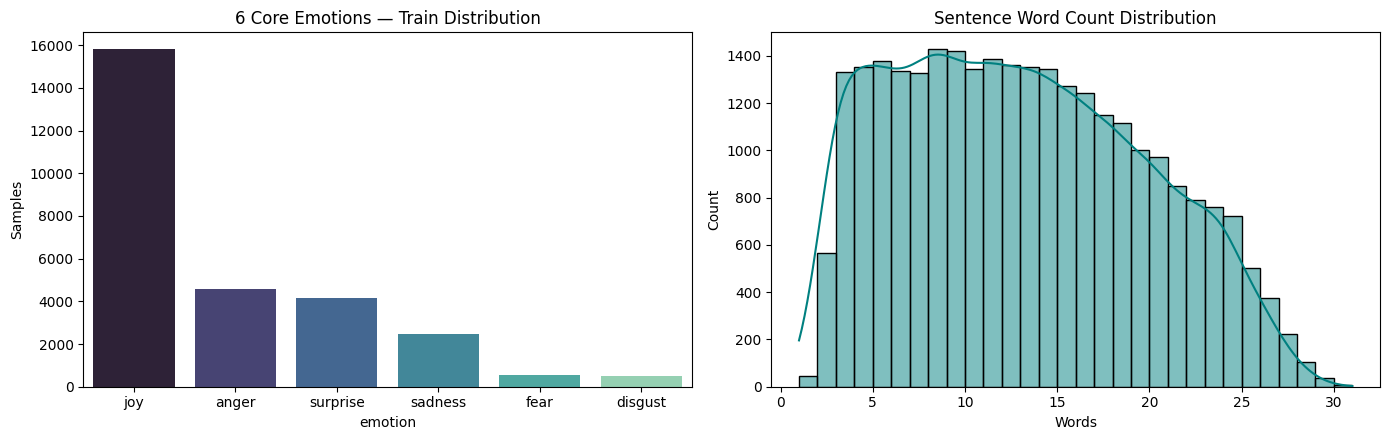

Word length percentiles [50, 75, 90, 95, 99]: [12 18 22 24 27]


In [5]:
# Explore class distribution and text lengths
counts = train_df["emotion"].value_counts()
pcts = (counts / len(train_df) * 100).round(2)
display(pd.DataFrame({"Train Count": counts, "Percentage (%)": pcts}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=counts.index, y=counts.values, palette="mako", ax=axes[0])
axes[0].set_title("6 Core Emotions — Train Distribution")
axes[0].set_ylabel("Samples")

word_lens = train_df["text"].str.split().str.len()
sns.histplot(word_lens.clip(upper=60), bins=30, kde=True, color="teal", ax=axes[1])
axes[1].set_title("Sentence Word Count Distribution")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

print("Word length percentiles [50, 75, 90, 95, 99]:", np.percentile(word_lens, [50, 75, 90, 95, 99]).astype(int))


## 3. Text Cleaning, Label Encoding, Tokenization & Padding


In [6]:
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer


def clean_text(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


for split_df in (train_df, val_df, test_df):
    split_df["clean_text"] = split_df["text"].apply(clean_text)

# Encode 6 emotion classes
label_encoder = LabelEncoder()
train_df["label_id"] = label_encoder.fit_transform(train_df["emotion"])
val_df["label_id"] = label_encoder.transform(val_df["emotion"])
test_df["label_id"] = label_encoder.transform(test_df["emotion"])

NUM_CLASSES = len(label_encoder.classes_)
ID2LABEL = {i: lbl for i, lbl in enumerate(label_encoder.classes_)}
LABEL2ID = {lbl: i for i, lbl in enumerate(label_encoder.classes_)}
print("Target Classes:", ID2LABEL)

# Compute balanced class weights (important because disgust & fear are smaller classes)
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=train_df["label_id"].values,
)
CLASS_WEIGHT_DICT = {i: float(w) for i, w in enumerate(class_weights_arr)}
print("Class Weights:", {ID2LABEL[k]: round(v, 3) for k, v in CLASS_WEIGHT_DICT.items()})

# Tokenize & pad
MAX_VOCAB_SIZE = 20000
MAX_LEN = 48

keras_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE, oov_token="<OOV>")
keras_tokenizer.fit_on_texts(train_df["clean_text"])

X_train = pad_sequences(keras_tokenizer.texts_to_sequences(train_df["clean_text"]), maxlen=MAX_LEN, padding="post", truncating="post")
X_val = pad_sequences(keras_tokenizer.texts_to_sequences(val_df["clean_text"]), maxlen=MAX_LEN, padding="post", truncating="post")
X_test = pad_sequences(keras_tokenizer.texts_to_sequences(test_df["clean_text"]), maxlen=MAX_LEN, padding="post", truncating="post")

y_train = train_df["label_id"].values
y_val = val_df["label_id"].values
y_test = test_df["label_id"].values

print("Padded shapes:", X_train.shape, X_val.shape, X_test.shape)


Target Classes: {0: 'anger', 1: 'disgust', 2: 'fear', 3: 'joy', 4: 'sadness', 5: 'surprise'}
Class Weights: {'anger': 1.02, 'disgust': 8.939, 'fear': 8.276, 'joy': 0.296, 'sadness': 1.908, 'surprise': 1.126}
Padded shapes: (28104, 48) (3527, 48) (3539, 48)


## 4. Pre-trained GloVe Embeddings (`glove.6B.100d`)


In [9]:
!pip -q install gensim
import gensim.downloader as api

EMBEDDING_DIM = 100
print("Loading pre-trained GloVe 100d via gensim...")
glove_vectors = api.load("glove-wiki-gigaword-100")

vocab_size = min(MAX_VOCAB_SIZE, len(keras_tokenizer.word_index) + 1)
embedding_matrix = np.random.normal(0, 0.05, (vocab_size, EMBEDDING_DIM)).astype("float32")
embedding_matrix[0] = 0.0  # padding token

hits = 0
for word, idx in keras_tokenizer.word_index.items():
    if idx >= vocab_size:
        continue
    if word in glove_vectors:
        embedding_matrix[idx] = glove_vectors[word]
        hits += 1

print(f"Vocab size: {vocab_size} | GloVe coverage: {hits}/{vocab_size} ({hits/vocab_size*100:.1f}%)")

Loading pre-trained GloVe 100d via gensim...
[==================================================] 100.0% 128.1/128.1MB downloaded
Vocab size: 20000 | GloVe coverage: 17460/20000 (87.3%)


## 5. Build & Train 3 Custom Architectures: LSTM, GRU, BiLSTM + Attention


In [10]:
from tensorflow.keras import callbacks, layers, models


class BahdanauAttention(layers.Layer):
    """Additive Attention over sequence hidden states; returns (context_vector, attention_weights)."""

    def __init__(self, units: int = 64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.W = layers.Dense(units, activation="tanh")
        self.V = layers.Dense(1)

    def call(self, hidden_states, mask=None):
        score = self.V(self.W(hidden_states))  # (batch, seq_len, 1)
        if mask is not None:
            mask_f = tf.cast(mask[:, :, tf.newaxis], dtype=score.dtype)
            score = score + (1.0 - mask_f) * -1e9
        weights = tf.nn.softmax(score, axis=1)  # (batch, seq_len, 1)
        context = tf.reduce_sum(weights * hidden_states, axis=1)  # (batch, hidden_dim)
        return context, tf.squeeze(weights, axis=-1)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"units": self.units})
        return cfg


def build_rnn_model(arch: str):
    inputs = layers.Input(shape=(MAX_LEN,), name="token_ids")
    mask = layers.Lambda(lambda t: tf.not_equal(t, 0))(inputs)

    emb = layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        trainable=True,
        name="glove_embedding",
    )(inputs)
    x = layers.SpatialDropout1D(0.25)(emb)

    if arch == "LSTM":
        x = layers.LSTM(128, dropout=0.2)(x, mask=mask)
    elif arch == "GRU":
        x = layers.GRU(128, dropout=0.2)(x, mask=mask)
    elif arch == "BiLSTM+Attention":
        seq_out = layers.Bidirectional(layers.LSTM(96, return_sequences=True, dropout=0.2))(x, mask=mask)
        x, attn_weights = BahdanauAttention(64, name="attention_layer")(seq_out, mask=mask)
    else:
        raise ValueError(arch)

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="emotion_probs")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name=arch.replace("+", "_"))
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    if arch == "BiLSTM+Attention":
        attn_extractor = models.Model(inputs=inputs, outputs=[outputs, attn_weights], name="BiLSTM_Attention_Extractor")
        return model, attn_extractor
    return model, None


EPOCHS = 10
BATCH_SIZE = 128

keras_models = {}
keras_histories = {}
model_predictions = {}
attn_model = None

for arch in ["LSTM", "GRU", "BiLSTM+Attention"]:
    print(f"\n{'='*60}\nTraining {arch} (GloVe-initialized)...\n{'='*60}")
    model, extractor = build_rnn_model(arch)
    if extractor is not None:
        attn_model = extractor

    cb = [
        callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5),
    ]
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHT_DICT,
        callbacks=cb,
        verbose=1,
    )
    keras_models[arch] = model
    keras_histories[arch] = hist.history
    probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
    model_predictions[arch] = np.argmax(probs, axis=1)



Training LSTM (GloVe-initialized)...
Epoch 1/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 30s 38ms/step - accuracy: 0.3049 - loss: 1.7165 - val_accuracy: 0.4990 - val_loss: 1.3487 - learning_rate: 0.0010
Epoch 2/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.4918 - loss: 1.4155 - val_accuracy: 0.6408 - val_loss: 0.9821 - learning_rate: 0.0010
Epoch 3/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.5938 - loss: 1.1358 - val_accuracy: 0.6473 - val_loss: 0.9429 - learning_rate: 0.0010
Epoch 4/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - accuracy: 0.6428 - loss: 0.9745 - val_accuracy: 0.6793 - val_loss: 0.8603 - learning_rate: 0.0010
Epoch 5/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 7s 31ms/step - accuracy: 0.6746 - loss: 0.8843 - val_accuracy: 0.6918 - val_loss: 0.8405 - learning_rate: 0.0010
Epoch 6/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.7037 - loss: 0.7963 - val_accuracy: 0.7074 - val_loss: 0.8159 - learning_rate: 0.0010
Epoch 7/10
220/220 ━━━━━━━━━━━━━━━━━━━━ 9s 

## 6. Fine-Tune DistilBERT Using HuggingFace Trainer API


In [11]:
from datasets import Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)

TRANSFORMER_NAME = "distilbert-base-uncased"
HF_MAX_LEN = 96

hf_tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_NAME)


def tokenize_fn(batch):
    return hf_tokenizer(batch["text"], truncation=True, max_length=HF_MAX_LEN)


hf_train = Dataset.from_pandas(train_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_fn, batched=True, remove_columns=["text"])
hf_val = Dataset.from_pandas(val_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_fn, batched=True, remove_columns=["text"])
hf_test = Dataset.from_pandas(test_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_fn, batched=True, remove_columns=["text"])


class WeightedTrainer(Trainer):
    def __init__(self, weights_tensor, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.weights_tensor = weights_tensor

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = torch.nn.CrossEntropyLoss(weight=self.weights_tensor.to(logits.device))
        loss = loss_fn(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }


hf_model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_NAME,
    num_labels=NUM_CLASSES,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

training_args = TrainingArguments(
    output_dir="./distilbert_emotion_ckpts",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    weights_tensor=torch.tensor(class_weights_arr, dtype=torch.float32),
    model=hf_model,
    args=training_args,
    train_dataset=hf_train,
    eval_dataset=hf_val,
    processing_class=hf_tokenizer,
    data_collator=DataCollatorWithPadding(hf_tokenizer),
    compute_metrics=compute_metrics,
)

trainer.train()
test_out = trainer.predict(hf_test)
model_predictions["DistilBERT"] = np.argmax(test_out.predictions, axis=-1)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

... (5 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.828345,0.759626,0.777715,0.668225
2,0.618719,0.738829,0.783952,0.682749
3,0.506583,0.784638,0.794159,0.690122


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 7. Evaluation & 4-Model Comparison (Accuracy, Macro F1, Per-Class Report, Confusion Matrices)


,Model,Accuracy,Macro F1,Weighted F1,Macro Precision,Macro Recall
0,DistilBERT,0.7926,0.6982,0.7984,0.6628,0.7481
1,BiLSTM+Attention,0.7299,0.6386,0.7387,0.5989,0.7033
2,LSTM,0.7104,0.6227,0.7223,0.5933,0.6825
3,GRU,0.7090,0.6062,0.7177,0.5716,0.6830


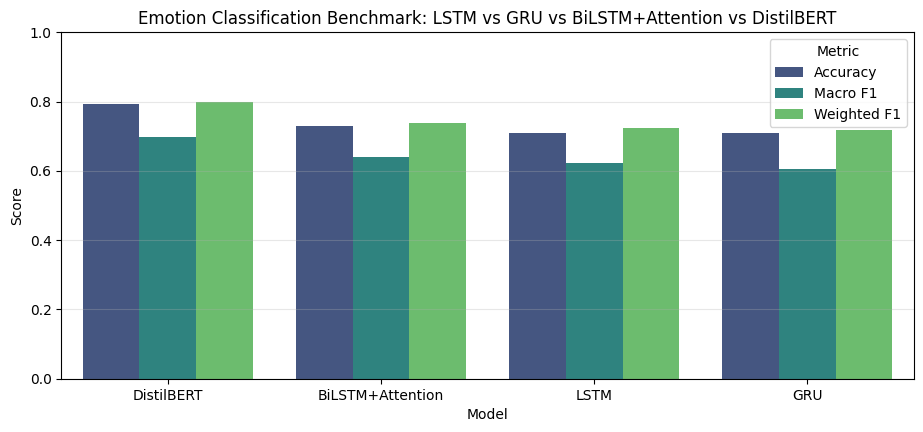

In [12]:
rows = []
for name, preds in model_predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Macro F1": round(f1_score(y_test, preds, average="macro", zero_division=0), 4),
        "Weighted F1": round(f1_score(y_test, preds, average="weighted", zero_division=0), 4),
        "Macro Precision": round(precision_score(y_test, preds, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_test, preds, average="macro", zero_division=0), 4),
    })

results_df = pd.DataFrame(rows).sort_values(by="Macro F1", ascending=False).reset_index(drop=True)
display(results_df)

plot_df = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Macro F1", "Weighted F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(11, 4.5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
plt.ylim(0, 1.0)
plt.title("Emotion Classification Benchmark: LSTM vs GRU vs BiLSTM+Attention vs DistilBERT")
plt.grid(axis="y", alpha=0.3)
plt.show()


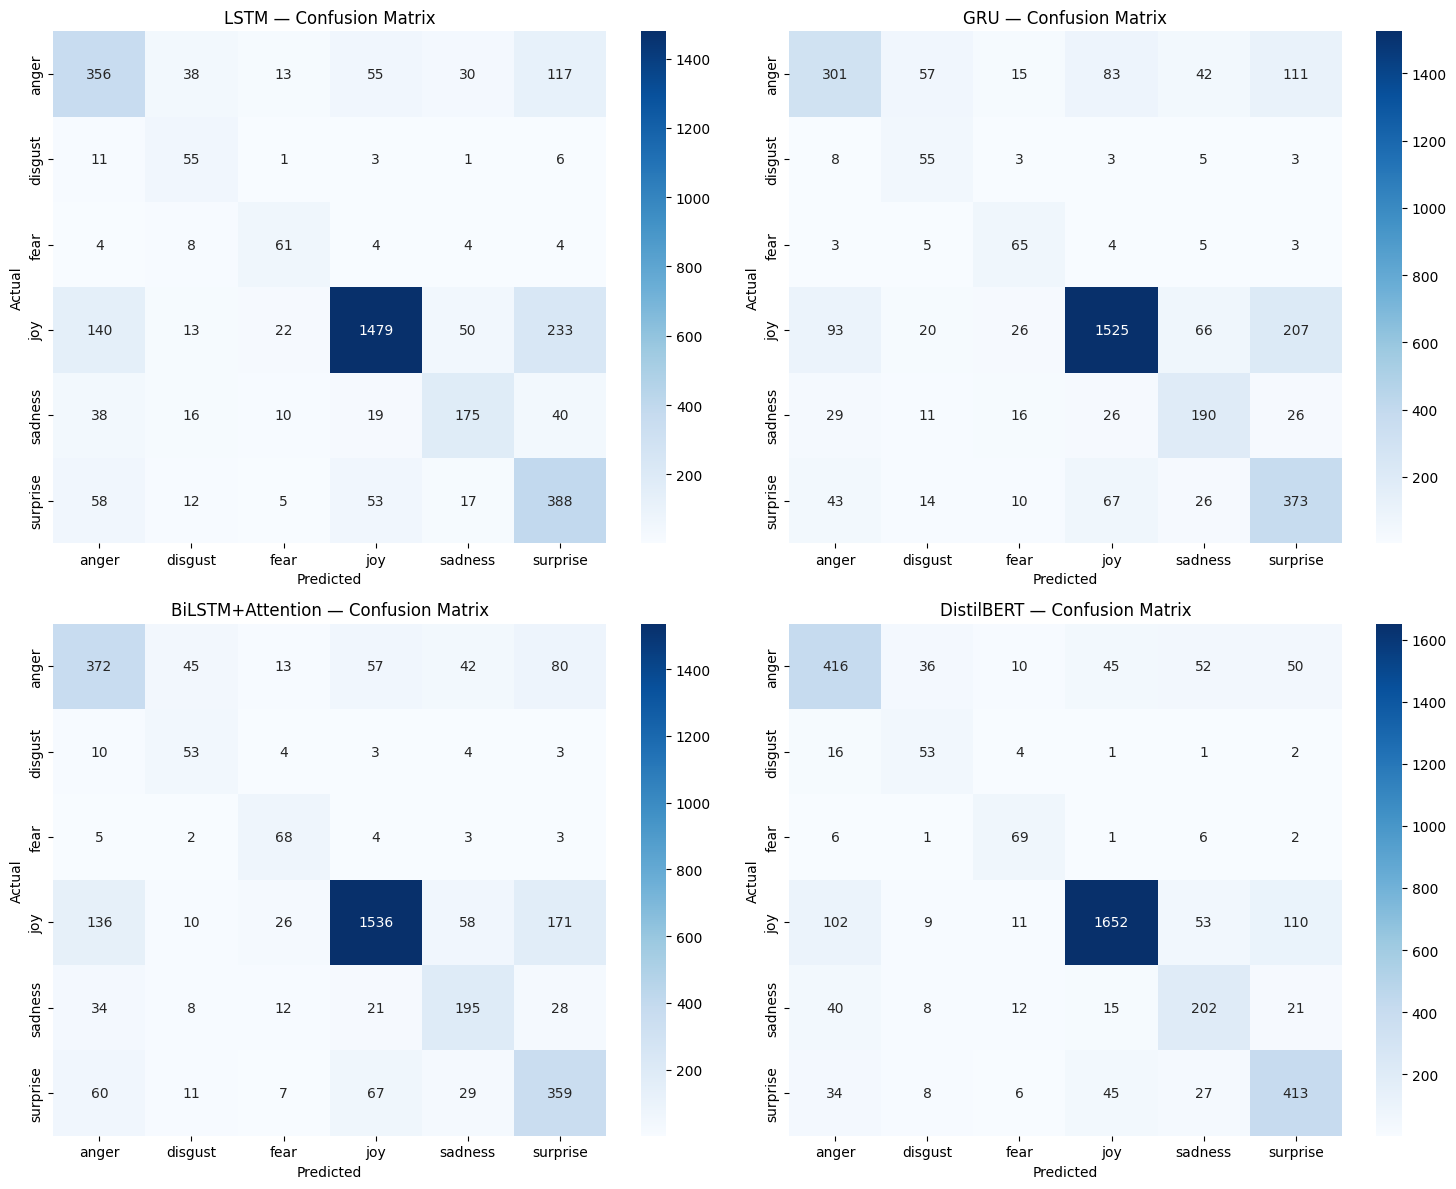

Best Model: DistilBERT

              precision    recall  f1-score   support

       anger       0.68      0.68      0.68       609
     disgust       0.46      0.69      0.55        77
        fear       0.62      0.81      0.70        85
         joy       0.94      0.85      0.89      1937
     sadness       0.59      0.68      0.63       298
    surprise       0.69      0.77      0.73       533

    accuracy                           0.79      3539
   macro avg       0.66      0.75      0.70      3539
weighted avg       0.81      0.79      0.80      3539



In [13]:
class_names = [ID2LABEL[i] for i in range(NUM_CLASSES)]
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

for idx, (name, preds) in enumerate(model_predictions.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[idx])
    axes[idx].set_title(f"{name} — Confusion Matrix")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print(f"Best Model: {best_model_name}\n")
print(classification_report(y_test, model_predictions[best_model_name], target_names=class_names))


## 8. Attention Weight Heatmaps (Interpreting Word-Level Predictions)


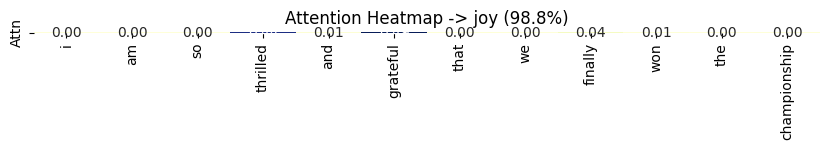

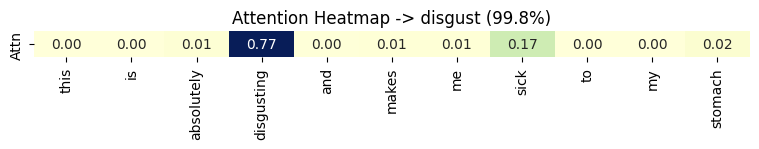

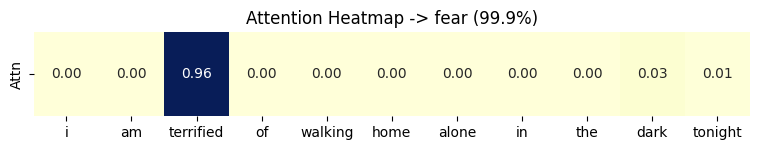

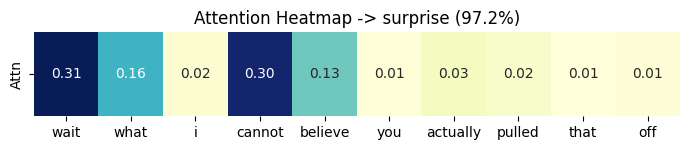

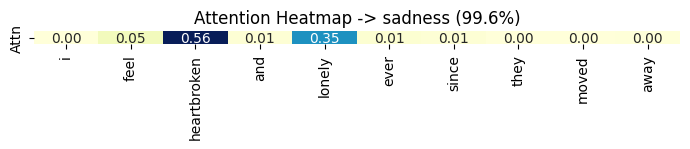

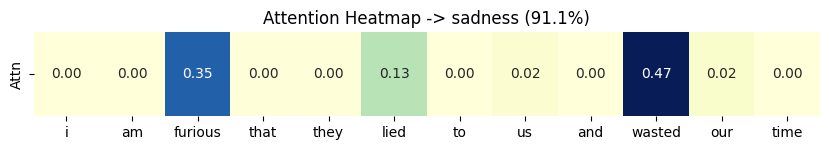

In [14]:
def visualize_attention(sentence: str):
    cleaned = clean_text(sentence)
    tokens = cleaned.split()[:MAX_LEN]
    seq = keras_tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")

    probs, weights = attn_model.predict(padded, verbose=0)
    pred_id = int(np.argmax(probs[0]))
    pred_label = ID2LABEL[pred_id]
    conf = float(probs[0][pred_id]) * 100

    token_weights = weights[0][:len(tokens)]
    norm_w = token_weights / (token_weights.max() + 1e-8)

    # 1. Color-highlighted HTML tokens
    spans = []
    for tok, w in zip(tokens, norm_w):
        alpha = round(float(w) * 0.85, 2)
        spans.append(
            f'<span style="background:rgba(14,165,233,{alpha});padding:3px 6px;margin:2px;border-radius:4px;display:inline-block;">{tok}</span>'
        )
    display(HTML(f"<p><b>Predicted:</b> {pred_label} ({conf:.1f}%)<br>{' '.join(spans)}</p>"))

    # 2. 1D Attention Heatmap
    plt.figure(figsize=(max(6, len(tokens) * 0.7), 1.6))
    sns.heatmap(
        [token_weights],
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        xticklabels=tokens,
        yticklabels=["Attn"],
        cbar=False,
    )
    plt.title(f"Attention Heatmap -> {pred_label} ({conf:.1f}%)")
    plt.tight_layout()
    plt.show()


sample_sentences = [
    "I am so thrilled and grateful that we finally won the championship!",
    "This is absolutely disgusting and makes me sick to my stomach.",
    "I am terrified of walking home alone in the dark tonight.",
    "Wait what?! I cannot believe you actually pulled that off!",
    "I feel heartbroken and lonely ever since they moved away.",
    "I am furious that they lied to us and wasted our time.",
]

for s in sample_sentences:
    visualize_attention(s)


## 9. Save Best Model & Results for Download


In [15]:
SAVE_DIR = Path("saved_emotion_model")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(SAVE_DIR / "model_comparison.csv", index=False)
report_txt = classification_report(y_test, model_predictions[best_model_name], target_names=class_names)
(SAVE_DIR / "classification_report.txt").write_text(report_txt, encoding="utf-8")

if best_model_name == "DistilBERT":
    trainer.save_model(str(SAVE_DIR / "transformer"))
    hf_tokenizer.save_pretrained(str(SAVE_DIR / "transformer"))

meta = {
    "best_model": best_model_name,
    "id2label": {str(k): v for k, v in ID2LABEL.items()},
    "max_len": HF_MAX_LEN,
}
(SAVE_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("Saved artifacts to:", SAVE_DIR.resolve())


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved artifacts to: /content/saved_emotion_model


In [17]:
# Upgraded Transformer: RoBERTa-base + Dampened Class Weights + Warmup + Label Smoothing
UPGRADED_MODEL = "roberta-base"
rob_tokenizer = AutoTokenizer.from_pretrained(UPGRADED_MODEL)

def tokenize_rob(batch):
    return rob_tokenizer(batch["text"], truncation=True, max_length=96)

rob_train = Dataset.from_pandas(train_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_rob, batched=True, remove_columns=["text"])
rob_val = Dataset.from_pandas(val_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_rob, batched=True, remove_columns=["text"])
rob_test = Dataset.from_pandas(test_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tokenize_rob, batched=True, remove_columns=["text"])

# Dampened (sqrt) class weights -> much better Precision & Accuracy while keeping strong Recall
smooth_weights = torch.tensor(np.sqrt(class_weights_arr), dtype=torch.float32)

class SmoothWeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = torch.nn.CrossEntropyLoss(
            weight=smooth_weights.to(logits.device),
            label_smoothing=0.05,
        )
        loss = loss_fn(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

rob_model = AutoModelForSequenceClassification.from_pretrained(
    UPGRADED_MODEL, num_labels=NUM_CLASSES, id2label=ID2LABEL, label2id=LABEL2ID
)

rob_args = TrainingArguments(
    output_dir="./roberta_emotion_ckpts",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    lr_scheduler_type="cosine",
    warmup_steps=200,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

rob_trainer = SmoothWeightedTrainer(
    model=rob_model,
    args=rob_args,
    train_dataset=rob_train,
    eval_dataset=rob_val,
    processing_class=rob_tokenizer,
    data_collator=DataCollatorWithPadding(rob_tokenizer),
    compute_metrics=compute_metrics,
)

rob_trainer.train()
rob_preds = np.argmax(rob_trainer.predict(rob_test).predictions, axis=-1)
print(f"RoBERTa Accuracy: {accuracy_score(y_test, rob_preds):.4f} | Macro F1: {f1_score(y_test, rob_preds, average='macro'):.4f}")
print(classification_report(y_test, rob_preds, target_names=class_names))

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.000321,0.949658,0.817976,0.702736
2,0.896154,0.944899,0.811171,0.703802
3,0.768469,0.954697,0.833286,0.728606
4,0.722561,0.981140,0.828750,0.721227


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

RoBERTa Accuracy: 0.8217 | Macro F1: 0.7296
              precision    recall  f1-score   support

       anger       0.71      0.75      0.73       609
     disgust       0.57      0.60      0.58        77
        fear       0.69      0.79      0.74        85
         joy       0.92      0.90      0.91      1937
     sadness       0.67      0.68      0.68       298
    surprise       0.75      0.74      0.75       533

    accuracy                           0.82      3539
   macro avg       0.72      0.74      0.73      3539
weighted avg       0.83      0.82      0.82      3539



In [20]:
!pip -q install sentencepiece
from scipy.special import softmax

# 1. Train DeBERTa-v3-base (in float32 to avoid FP16 unscale error on T4)
DEB_NAME = "microsoft/deberta-v3-base"
deb_tok = AutoTokenizer.from_pretrained(DEB_NAME)

def tok_deb(batch):
    return deb_tok(batch["text"], truncation=True, max_length=96)

deb_train = Dataset.from_pandas(train_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tok_deb, batched=True, remove_columns=["text"])
deb_val = Dataset.from_pandas(val_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tok_deb, batched=True, remove_columns=["text"])
deb_test = Dataset.from_pandas(test_df[["text", "label_id"]].rename(columns={"label_id": "label"})).map(tok_deb, batched=True, remove_columns=["text"])

deb_model = AutoModelForSequenceClassification.from_pretrained(
    DEB_NAME,
    num_labels=NUM_CLASSES,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
    torch_dtype=torch.float32,
)

deb_args = TrainingArguments(
    output_dir="./deberta_emotion_ckpts",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=1.5e-5,
    lr_scheduler_type="cosine",
    warmup_steps=200,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=4,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    fp16=False,
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

deb_trainer = SmoothWeightedTrainer(
    model=deb_model,
    args=deb_args,
    train_dataset=deb_train,
    eval_dataset=deb_val,
    processing_class=deb_tok,
    data_collator=DataCollatorWithPadding(deb_tok),
    compute_metrics=compute_metrics,
)

deb_trainer.train()

# 2. Soft-Voting Ensemble: DeBERTa-v3 (45%) + RoBERTa (35%) + DistilBERT (20%)
p_deb = softmax(deb_trainer.predict(deb_test).predictions, axis=-1)
p_rob = softmax(rob_trainer.predict(rob_test).predictions, axis=-1)
p_dis = softmax(test_out.predictions, axis=-1)

ens_probs = 0.45 * p_deb + 0.35 * p_rob + 0.20 * p_dis
ens_preds = np.argmax(ens_probs, axis=-1)

print(f"DeBERTa-v3 Alone  -> Acc: {accuracy_score(y_test, np.argmax(p_deb, -1)):.4f} | Macro F1: {f1_score(y_test, np.argmax(p_deb, -1), average='macro'):.4f}")
print(f"3-Model Ensemble  -> Acc: {accuracy_score(y_test, ens_preds):.4f} | Macro F1: {f1_score(y_test, ens_preds, average='macro'):.4f}")
print(classification_report(y_test, ens_preds, target_names=class_names))

Map:   0%|          | 0/28104 [00:00<?, ? examples/s]

Map:   0%|          | 0/3527 [00:00<?, ? examples/s]

Map:   0%|          | 0/3539 [00:00<?, ? examples/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DeBERTa-v3 Alone  -> Acc: 0.8197 | Macro F1: 0.7277
3-Model Ensemble  -> Acc: 0.8293 | Macro F1: 0.7400
              precision    recall  f1-score   support

       anger       0.70      0.78      0.74       609
     disgust       0.61      0.57      0.59        77
        fear       0.71      0.80      0.75        85
         joy       0.93      0.90      0.92      1937
     sadness       0.69      0.68      0.69       298
    surprise       0.76      0.77      0.76       533

    accuracy                           0.83      3539
   macro avg       0.73      0.75      0.74      3539
weighted avg       0.83      0.83      0.83      3539



In [21]:
import json, shutil
from pathlib import Path
from google.colab import files

deb_preds = np.argmax(p_deb, axis=-1)
extra_rows = [
    {
        "Model": "RoBERTa-base",
        "Accuracy": round(accuracy_score(y_test, np.argmax(p_rob, -1)), 4),
        "Macro F1": round(f1_score(y_test, np.argmax(p_rob, -1), average="macro", zero_division=0), 4),
        "Weighted F1": round(f1_score(y_test, np.argmax(p_rob, -1), average="weighted", zero_division=0), 4),
        "Macro Precision": round(precision_score(y_test, np.argmax(p_rob, -1), average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_test, np.argmax(p_rob, -1), average="macro", zero_division=0), 4),
    },
    {
        "Model": "DeBERTa-v3-base",
        "Accuracy": round(accuracy_score(y_test, deb_preds), 4),
        "Macro F1": round(f1_score(y_test, deb_preds, average="macro", zero_division=0), 4),
        "Weighted F1": round(f1_score(y_test, deb_preds, average="weighted", zero_division=0), 4),
        "Macro Precision": round(precision_score(y_test, deb_preds, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_test, deb_preds, average="macro", zero_division=0), 4),
    },
    {
        "Model": "3-Model Ensemble",
        "Accuracy": round(accuracy_score(y_test, ens_preds), 4),
        "Macro F1": round(f1_score(y_test, ens_preds, average="macro", zero_division=0), 4),
        "Weighted F1": round(f1_score(y_test, ens_preds, average="weighted", zero_division=0), 4),
        "Macro Precision": round(precision_score(y_test, ens_preds, average="macro", zero_division=0), 4),
        "Macro Recall": round(recall_score(y_test, ens_preds, average="macro", zero_division=0), 4),
    },
]
updated_results = pd.concat([results_df, pd.DataFrame(extra_rows)], ignore_index=True).sort_values(by="Macro F1", ascending=False)

SAVE_DIR = Path("saved_emotion_model")
shutil.rmtree(SAVE_DIR / "transformer", ignore_errors=True)
SAVE_DIR.mkdir(parents=True, exist_ok=True)

deb_trainer.save_model(str(SAVE_DIR / "transformer"))
deb_tok.save_pretrained(str(SAVE_DIR / "transformer"))
updated_results.to_csv(SAVE_DIR / "model_comparison.csv", index=False)
(SAVE_DIR / "classification_report.txt").write_text(
    classification_report(y_test, deb_preds, target_names=class_names), encoding="utf-8"
)
(SAVE_DIR / "model_meta.json").write_text(
    json.dumps({"best_model": "DeBERTa-v3-base", "id2label": {str(k): v for k, v in ID2LABEL.items()}, "max_len": 96}, indent=2),
    encoding="utf-8",
)

zip_path = shutil.make_archive("emotion_model_and_results", "zip", ".", "saved_emotion_model")
files.download(zip_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

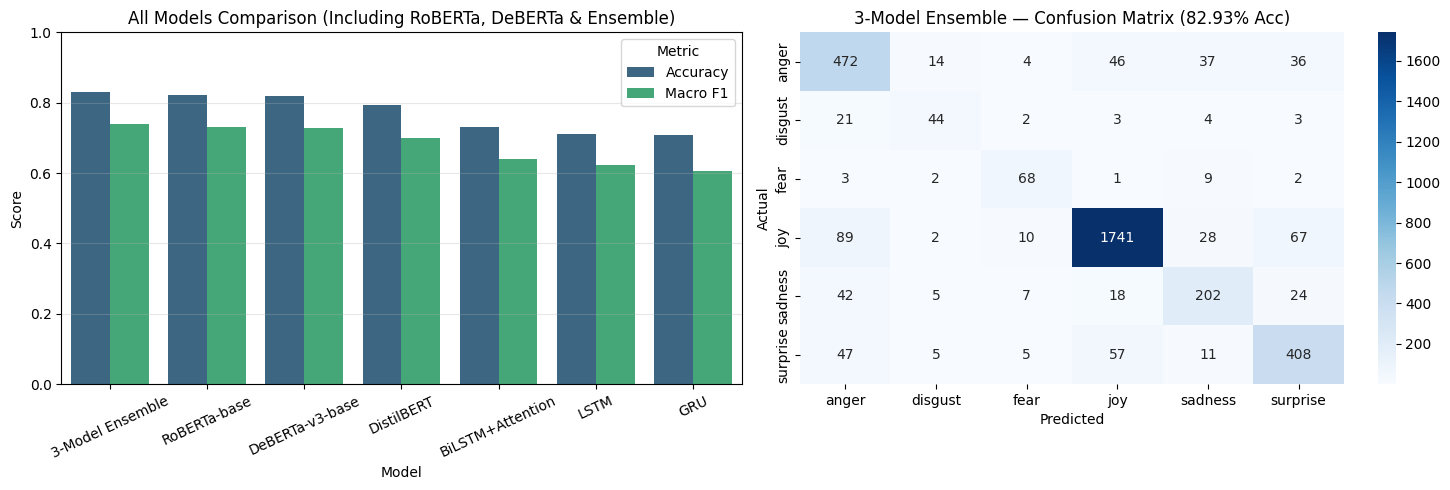

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Updated Accuracy & Macro F1 Bar Chart
plot_upd = updated_results.melt(id_vars="Model", value_vars=["Accuracy", "Macro F1"], var_name="Metric", value_name="Score")
sns.barplot(data=plot_upd, x="Model", y="Score", hue="Metric", palette="viridis", ax=axes[0])
axes[0].set_ylim(0, 1.0)
axes[0].set_title("All Models Comparison (Including RoBERTa, DeBERTa & Ensemble)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.3)

# 2. 3-Model Ensemble Confusion Matrix
cm_ens = confusion_matrix(y_test, ens_preds)
sns.heatmap(cm_ens, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title("3-Model Ensemble — Confusion Matrix (82.93% Acc)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()